# Linear Classification on CIFAR-10

Exploring class scores $f(x) = Wx + b$, Multiclass SVM Hinge Loss, Softmax probabilities, and weight templates on CIFAR-10 using randomly initialized weights.

In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', 15)
pd.set_option('display.precision', 4)

data_dir = next(p for p in ['cifar-10-batches-py', '../knn/cifar-10-batches-py', 'knn/cifar-10-batches-py'] if os.path.exists(p))
with open(os.path.join(data_dir, 'batches.meta'), 'rb') as f:
    class_names = [n.decode('utf-8') for n in pickle.load(f, encoding='bytes')[b'label_names']]
with open(os.path.join(data_dir, 'test_batch'), 'rb') as f:
    batch = pickle.load(f, encoding='bytes')

X_imgs = batch[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
y_all = np.array(batch[b'labels'], dtype=np.int64)

# Select 10 example images and flatten to 3072-D vectors
N = 10
imgs = X_imgs[:N]
X = imgs.reshape(N, -1).astype(np.float64)
y = y_all[:N]
print(f"Selected examples: X={X.shape}, y={y.shape}, classes={class_names}")

Selected examples: X=(10, 3072), y=(10,), classes=['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### 1. Weight Initialization & Linear Score Function $f(x) = Wx + b$
- Initialize $W \in \mathbb{R}^{10 \times 3072} \sim \mathcal{N}(0, (10^{-4})^2)$ and $b = \mathbf{0} \in \mathbb{R}^{10}$ with `np.random.seed(0)`.
- Compute $s_i = W x_i + b$ and predict $\hat{y}_i = \arg\max_k s_{i,k}$.

In [2]:
np.random.seed(0)
W = np.random.randn(10, 3072) * 1e-4
b = np.zeros(10)

scores = X @ W.T + b
preds = np.argmax(scores, axis=1)

score_df = pd.DataFrame(scores, columns=class_names, index=[f"Img #{i}" for i in range(N)])
score_df['True'] = [class_names[c] for c in y]
score_df['Pred'] = [class_names[p] for p in preds]
score_df['Correct'] = preds == y
print(score_df)

        airplane  automobile    bird     cat    deer     dog    frog   horse    ship   truck        True   Pred  Correct
Img #0   -0.5017      0.4926 -0.8896 -0.6932  0.0859  0.6746  0.5754  0.0386 -0.4058 -0.9625         cat    dog    False
Img #1   -0.9084     -0.3774 -1.2439  0.3513  0.6157  0.9644  0.7469  0.5820 -0.7518 -2.1078        ship    dog    False
Img #2   -1.5158      0.0665 -0.8136  0.2106  0.3244  0.8372  0.7254  0.9020 -0.6509 -1.8073        ship  horse    False
Img #3   -1.2190     -0.0745 -1.0202  0.1978  0.5369  1.2059  1.4902  0.5016 -0.4915 -1.4006    airplane   frog    False
Img #4   -0.8395      0.0600 -1.2823 -0.3118  0.9667  0.4963  0.8666  0.0157  0.0009 -1.0249        frog   deer    False
Img #5   -0.3692     -0.1300 -1.0570 -0.2126  0.2785  0.7054  0.6323  0.1625  0.3888 -1.3571        frog    dog    False
Img #6    0.2073      0.0768 -0.4090 -0.1266  0.3489  0.2824  0.2665 -0.5620  0.1523 -1.3660  automobile   deer    False
Img #7   -0.5412     -0.0087 -0.

### 2. Multiclass SVM Hinge Loss
$$L_i = \sum_{j \neq y_i} \max(0, s_{i,j} - s_{i,y_i} + \Delta), \quad \Delta = 1.0, \qquad L = \frac{1}{N}\sum_{i=1}^N L_i$$

In [3]:
true_scores = scores[np.arange(N), y][:, None]
margins = np.maximum(0.0, scores - true_scores + 1.0)
margins[np.arange(N), y] = 0.0
svm_losses = margins.sum(axis=1)

svm_df = pd.DataFrame({
    'True': [class_names[c] for c in y],
    'True Score': scores[np.arange(N), y],
    'Pred': [class_names[p] for p in preds],
    'Max Score': scores.max(axis=1),
    'Hinge Loss (L_i)': svm_losses
}, index=[f"Img #{i}" for i in range(N)])
print(svm_df)
print(f"\nAverage Multiclass SVM Hinge Loss: {svm_losses.mean():.4f}")

              True  True Score   Pred  Max Score  Hinge Loss (L_i)
Img #0         cat     -0.6932    dog     0.6746           14.3462
Img #1        ship     -0.7518    dog     0.9644           14.7448
Img #2        ship     -0.6509  horse     0.9020           13.9440
Img #3    airplane     -1.2190   frog     1.4902           20.9166
Img #4        frog      0.8666   deer     0.9667            2.2067
Img #5        frog      0.6323    dog     0.7054            3.3987
Img #6  automobile      0.0768   deer     0.3489            7.5453
Img #7        frog      1.0077   frog     1.0077            1.0741
Img #8         cat     -0.4312   frog     1.2126           11.4220
Img #9  automobile      0.0018   frog     1.1995            8.0031

Average Multiclass SVM Hinge Loss: 9.7602


### 3. Softmax Probabilities & Comparison with Raw Scores
$$P(Y = k \mid X = x_i) = \frac{e^{s_{i,k}}}{\sum_{j=0}^9 e^{s_{i,j}}}$$
- **Raw scores vs. Probabilities**: Raw scores $s_k \in (-\infty, \infty)$ can be negative or positive, while Softmax exponentiates and normalizes them into $(0, 1)$ summing to $1.0$. Because $e^z$ is strictly increasing, Softmax preserves rank order ($\arg\max_k P_k = \arg\max_k s_k$).

        airplane  automobile    bird     cat    deer     dog    frog   horse    ship   truck  Sum   Pred
Img #0    0.0601      0.1625  0.0408  0.0496  0.1082  0.1949  0.1765  0.1032  0.0662  0.0379  1.0    dog
Img #1    0.0343      0.0583  0.0245  0.1208  0.1573  0.2230  0.1794  0.1521  0.0401  0.0103  1.0    dog
Img #2    0.0185      0.0900  0.0373  0.1039  0.1165  0.1945  0.1739  0.2075  0.0439  0.0138  1.0  horse
Img #3    0.0200      0.0627  0.0244  0.0823  0.1156  0.2256  0.2998  0.1116  0.0413  0.0167  1.0   frog
Img #4    0.0375      0.0921  0.0241  0.0635  0.2281  0.1425  0.2063  0.0881  0.0868  0.0311  1.0   deer
Img #5    0.0636      0.0808  0.0320  0.0744  0.1216  0.1864  0.1733  0.1083  0.1358  0.0237  1.0    dog
Img #6    0.1244      0.1091  0.0671  0.0890  0.1433  0.1340  0.1319  0.0576  0.1177  0.0258  1.0   deer
Img #7    0.0513      0.0874  0.0387  0.0560  0.1221  0.1234  0.2416  0.1308  0.0927  0.0559  1.0   frog
Img #8    0.0170      0.0776  0.0141  0.0534  0.1798  0

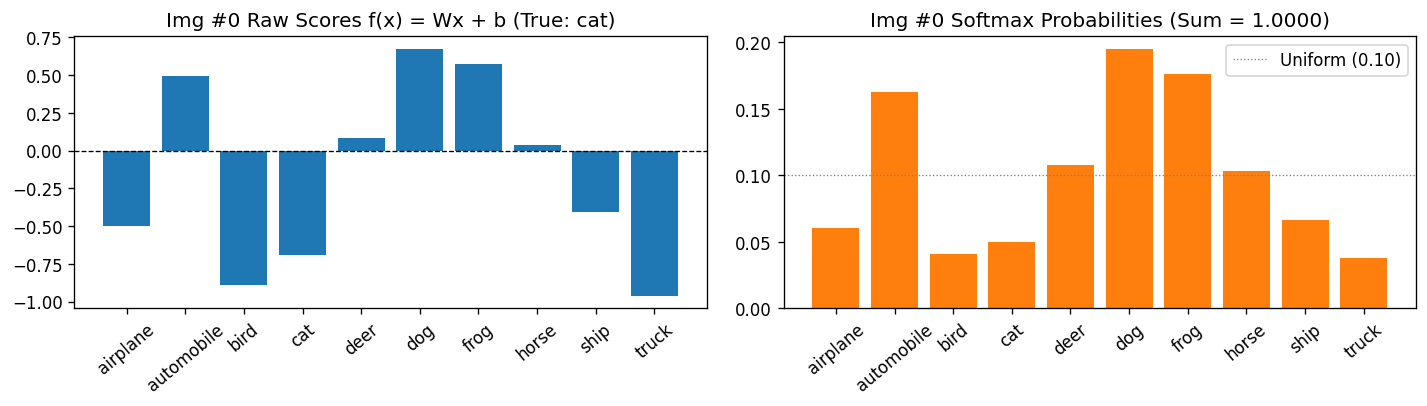

In [4]:
exp_scores = np.exp(scores - scores.max(axis=1, keepdims=True))
probs = exp_scores / exp_scores.sum(axis=1, keepdims=True)

prob_df = pd.DataFrame(probs, columns=class_names, index=[f"Img #{i}" for i in range(N)])
prob_df['Sum'] = probs.sum(axis=1)
prob_df['Pred'] = [class_names[p] for p in np.argmax(probs, axis=1)]
print(prob_df)
print(f"\nAll rows sum to 1.0: {np.allclose(probs.sum(axis=1), 1.0)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(class_names, scores[0], color='#1f77b4')
axes[0].axhline(0, color='k', lw=0.8, ls='--')
axes[0].set_title(f"Img #0 Raw Scores f(x) = Wx + b (True: {class_names[y[0]]})")
axes[0].tick_params(axis='x', rotation=40)

axes[1].bar(class_names, probs[0], color='#ff7f0e')
axes[1].axhline(0.1, color='gray', lw=0.8, ls=':', label='Uniform (0.10)')
axes[1].set_title(f"Img #0 Softmax Probabilities (Sum = {probs[0].sum():.4f})")
axes[1].tick_params(axis='x', rotation=40)
axes[1].legend()
plt.tight_layout()
plt.show()

### 4. Correctly Classified vs. Misclassified Examples
- **Explanation**: With untrained random weights, predictions are random projections over 10 classes ($\sim 10\%$ chance accuracy). Here **1 of 10 (`Img #7`, `frog`)** is classified correctly purely by chance alignment between random weights and pixel intensities, while the other 9 are misclassified.

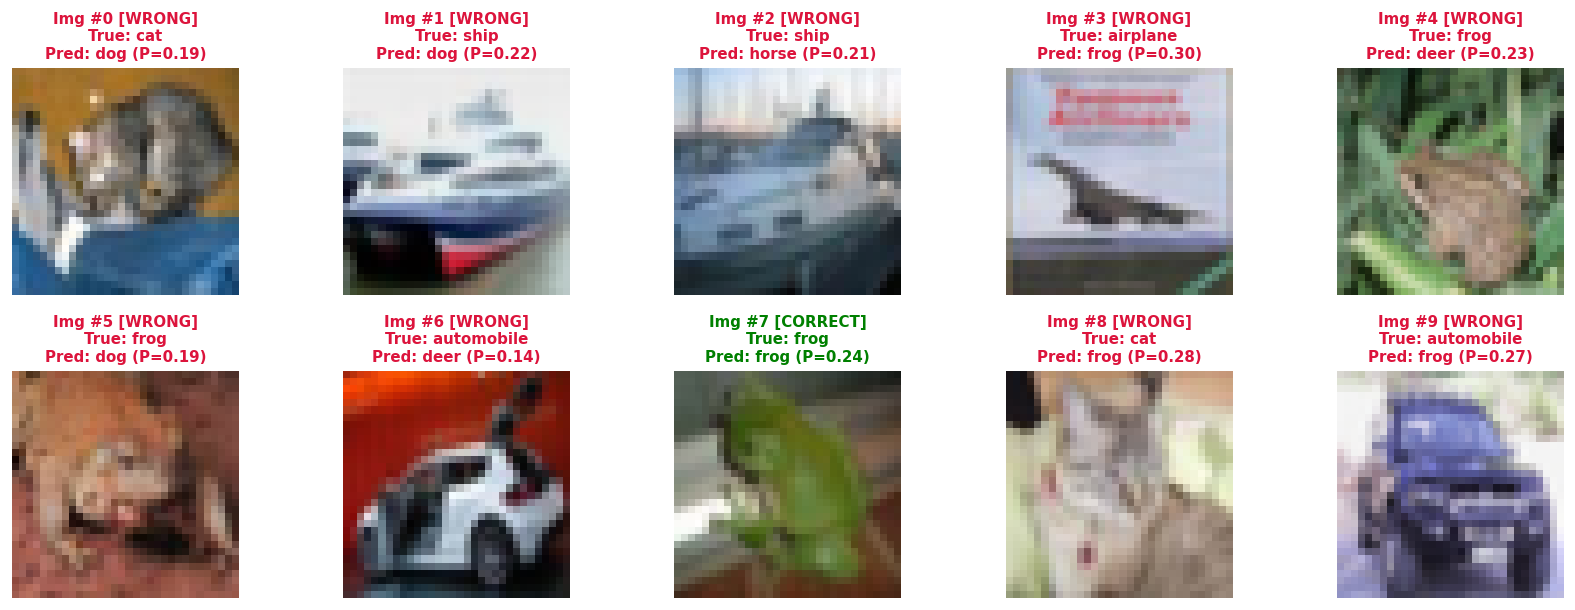

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(imgs[i])
    ax.axis('off')
    ok = preds[i] == y[i]
    tag = "CORRECT" if ok else "WRONG"
    ax.set_title(
        f"Img #{i} [{tag}]\nTrue: {class_names[y[i]]}\nPred: {class_names[preds[i]]} (P={probs[i, preds[i]]:.2f})",
        fontsize=9, color='green' if ok else 'crimson', fontweight='bold'
    )
plt.tight_layout()
plt.show()

### 5. Class Weight Visualization ($32 \times 32 \times 3$)
- **Explanation**: Each row $w_k \in \mathbb{R}^{3072}$ is sampled i.i.d. from $\mathcal{N}(0, \sigma^2)$ without training on CIFAR-10 data. Because adjacent pixels have zero spatial correlation and no gradient updates have occurred, the reshaped $32 \times 32 \times 3$ templates appear as pure RGB white noise rather than recognizable object shapes.

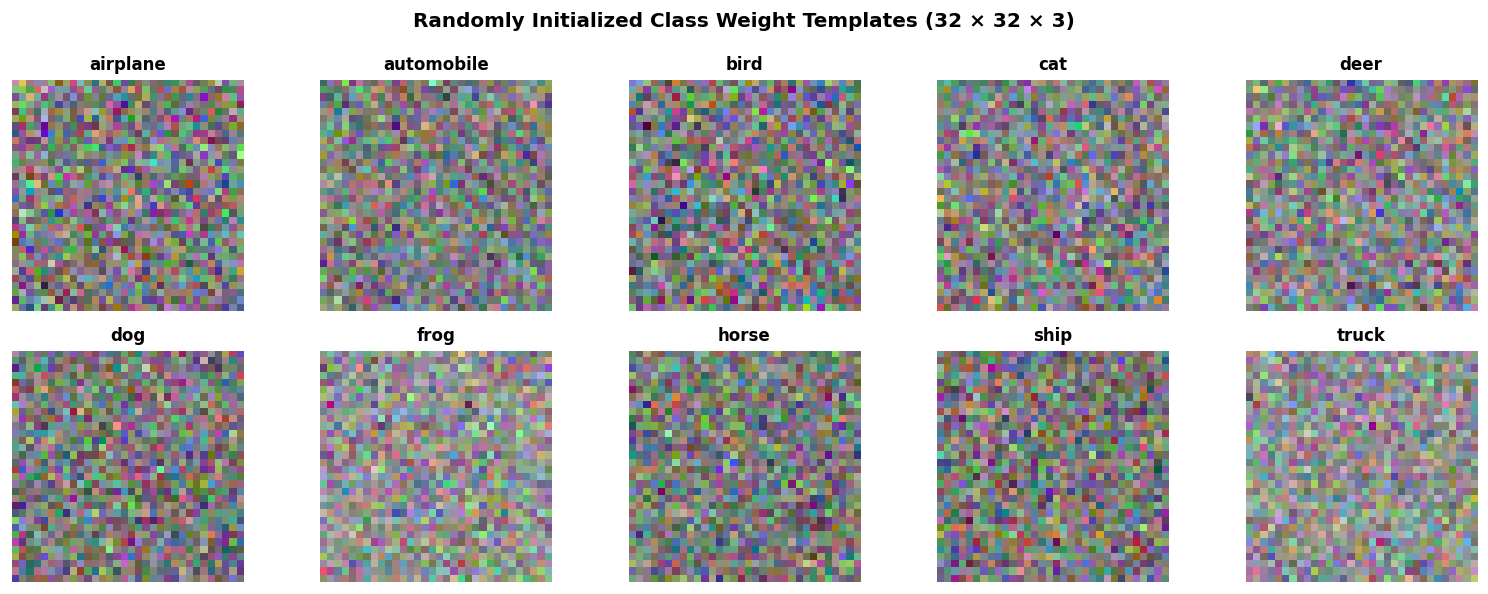

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for k, ax in enumerate(axes.flat):
    w_img = W[k].reshape(32, 32, 3)
    w_norm = (w_img - w_img.min()) / (w_img.max() - w_img.min())
    ax.imshow(w_norm)
    ax.set_title(class_names[k], fontsize=10, fontweight='bold')
    ax.axis('off')
plt.suptitle("Randomly Initialized Class Weight Templates (32 × 32 × 3)", fontweight='bold')
plt.tight_layout()
plt.show()